# FA&EFER – Emotion recognition **WITHOUT fairness** (baseline: train + test)

The same ResNet-50 + VGGFace2 model, data, seed and recipe as model 1 – but with every fairness mitigation removed:
**no class weights**, **best epoch chosen by accuracy**, **no ensemble / calibration**. It shows what the model does when it only optimises overall accuracy, so the effect of fairness can be measured.

**Fairness in this project** = every emotion should be recognised equally well. RAF-DB is very unbalanced (Happiness 4,772 training images, Fear 281) and has no demographic labels in our copy, so each emotion is treated as a group. Metrics: per-class recall, the gap and ratio between best and worst class (ratio ≥ 0.80 passes the *four-fifths rule*), balanced accuracy vs accuracy, and minority-class recall.

**Runs on Google Colab or locally** (Jupyter / VS Code with the project venv, opened from `D:\Research4` or `D:\Research4\notebooks`). It detects which one automatically.

* **Colab:** Runtime → Change runtime type → **GPU**. In Google Drive create `MyDrive/Sem3-CaseStudy` with `Dataset.zip` (zip of `TestDb/DATASET`) and `resnet50_ft_weight.pkl`. Checkpoints and results go to `MyDrive/Sem3-CaseStudy/models`.
* **Local:** uses `TestDb/DATASET` and `models/`. Models that are already trained (a `<name>.done` file next to them) are **not** retrained – the notebook only evaluates them.
* If Colab disconnects: reconnect, run the cells from the top again – training resumes from the last finished epoch.

Both notebooks save their test results to `models/`, and the **comparison cell** in either notebook shows *with vs without fairness* side by side once both have run.

| Setting | **With fairness** | **Without fairness (baseline)** |
|---|---|---|
| Network, data, seed, augmentation, schedule | same | same |
| Class weights in the loss | `(N / 7·n_c)^p`, p = 0.5 (model 1) / 0.3 (models 2–3) | none (`--class_weight_power 0`) |
| Best epoch chosen by | validation **macro-F1** (every emotion counts equally) | validation **accuracy** (majority classes dominate) |
| Ensemble + per-class calibration | yes (chosen on validation) | no |
| Checkpoint | `best_resnet50_vggface2_emotion.pth` (+ `emotion_r50_*`) | `emotion_r50_nofair.pth` |

## 1. Setup (Colab or local)

In [1]:
import os, sys, json, glob, random, subprocess
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR   = "/content/drive/MyDrive/Sem3-CaseStudy"  # folder on Google Drive
    DATASET_ZIP = f"{DRIVE_DIR}/Dataset.zip"              # zip of Dataset (train/1..7, test/1..7)
    WEIGHTS     = f"{DRIVE_DIR}/resnet50_ft_weight.pkl"   # VGGFace2 ResNet-50 weights
    MODELS_DIR  = f"{DRIVE_DIR}/models"                   # checkpoints + results (survive disconnects)
    DATA_DIR    = "/content/Dataset"                      # local copy for fast loading
    SCRIPT_DIR  = "/content/fer_scripts"
    WORKERS     = 2
else:  # local Jupyter / VS Code on the laptop - run from project directory
    here = os.path.abspath(os.getcwd())
    PROJECT_DIR = next((d for d in [here, os.path.dirname(here)]
                        if os.path.isdir(os.path.join(d, "TestDb", "DATASET"))), None)
    assert PROJECT_DIR, "Open this notebook from the project root or notebooks folder"
    DATA_DIR   = os.path.join(PROJECT_DIR, "TestDb", "DATASET")
    WEIGHTS    = os.path.join(PROJECT_DIR, "models", "resnet50_ft_weight.pkl")
    MODELS_DIR = os.path.join(PROJECT_DIR, "models")
    SCRIPT_DIR = os.path.join(PROJECT_DIR, "notebooks", "_nb_scripts")
    WORKERS    = 4

os.makedirs(MODELS_DIR, exist_ok=True); os.makedirs(SCRIPT_DIR, exist_ok=True)
sys.path.insert(0, SCRIPT_DIR)
EVAL_WORKERS = 0 if os.name == "nt" else WORKERS   # in-notebook DataLoader workers are unreliable on Windows
print("Colab" if IN_COLAB else "Local", "| data:", DATA_DIR, "| models:", MODELS_DIR)


Mounted at /content/drive
Colab | data: /content/Dataset | models: /content/drive/MyDrive/Sem3-CaseStudy/models


In [2]:
import torch, torchvision
print("torch", torch.__version__, "| torchvision", torchvision.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU. Training needs a GPU (Colab: Runtime > Change runtime type > GPU). "
          "Evaluation of already-trained models still works on CPU, slowly.")

torch 2.11.0+cu130 | torchvision 0.26.0+cu130
GPU: NVIDIA L4


In [3]:
# Colab already has everything these notebooks need (torch, torchvision, scikit-learn, matplotlib).
# Locally, use the project venv (requirements.txt).
import sklearn, matplotlib
print("scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

scikit-learn 1.6.1 | matplotlib 3.10.0


## 2. Dataset

Dataset successfully extracted to local Colab storage!
train {'Surprise': 1290, 'Fear': 281, 'Disgust': 717, 'Happiness': 4772, 'Sadness': 1982, 'Anger': 705, 'Neutral': 2524} total 12271
test {'Surprise': 329, 'Fear': 74, 'Disgust': 160, 'Happiness': 1185, 'Sadness': 478, 'Anger': 162, 'Neutral': 680} total 3068


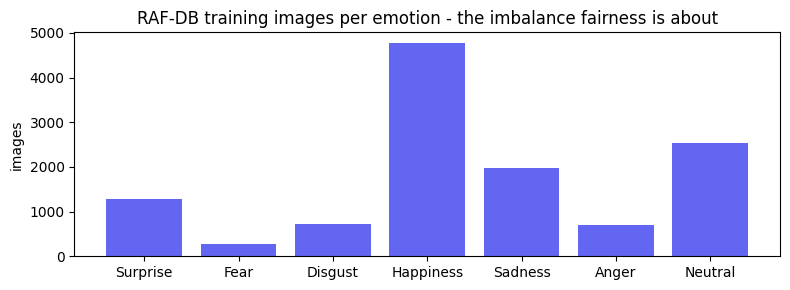

In [4]:
import zipfile, shutil, os

if IN_COLAB and not (os.path.isdir(f"{DATA_DIR}/train") and os.path.isdir(f"{DATA_DIR}/test")):
    # 1. Copy the zip file from Drive to local Colab storage
    !cp "/content/drive/MyDrive/Sem3-CaseStudy/Dataset.zip" "/content/Dataset.zip"

    # 2. Extract it locally
    with zipfile.ZipFile("/content/Dataset.zip", 'r') as zip_ref:
        zip_ref.extractall("/content/Dataset")

    print("Dataset successfully extracted to local Colab storage!")

    # Auto-detect train/ and test/ inside /content/Dataset
    if not (os.path.isdir(f"{DATA_DIR}/train") and os.path.isdir(f"{DATA_DIR}/test")):
        for root, dirs, _ in os.walk("/content/Dataset"):
            if "train" in dirs and "test" in dirs:
                DATA_DIR = root
                break

assert os.path.isdir(f"{DATA_DIR}/train") and os.path.isdir(f"{DATA_DIR}/test"), f"train/ and test/ not found in {DATA_DIR}"

import matplotlib.pyplot as plt
NAMES = ["Surprise", "Fear", "Disgust", "Happiness", "Sadness", "Anger", "Neutral"]
counts = {s: [len(glob.glob(f"{DATA_DIR}/{s}/{k}/*")) for k in range(1, 8)] for s in ["train", "test"]}
for s in counts:
    print(s, dict(zip(NAMES, counts[s])), "total", sum(counts[s]))
plt.figure(figsize=(8, 3))
plt.bar(NAMES, counts["train"], color="#6366f1")
plt.title("RAF-DB training images per emotion - the imbalance fairness is about"); plt.ylabel("images")
plt.tight_layout(); plt.show()


## 3. VGGFace2 ResNet-50 weights (needed only for training)

In [5]:
if not os.path.exists(WEIGHTS) and IN_COLAB:
    # resnet50_ft link from the README of github.com/cydonia999/VGGFace2-pytorch
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "gdown"], check=True)
    subprocess.run(["gdown", "--fuzzy", "https://drive.google.com/open?id=1A94PAAnwk6L7hXdBXLFosB_s0SzEhAFU", "-O", WEIGHTS])
if os.path.exists(WEIGHTS) and os.path.getsize(WEIGHTS) > 150e6:
    print("VGGFace2 weights OK:", round(os.path.getsize(WEIGHTS) / 1e6), "MB")
else:
    print("VGGFace2 weights NOT found at", WEIGHTS, "- needed only to TRAIN. Already-trained models can still be evaluated.")

VGGFace2 weights OK: 165 MB


## 4. Project scripts
The same training, ensemble and fairness code as the project (written to a scripts folder, so the notebook is self-contained).

In [6]:
# train_emotion_resnet50_vggface2.py - identical to the file in D:/Research4
open(os.path.join(SCRIPT_DIR, 'train_emotion_resnet50_vggface2.py'), "w", encoding="utf-8").write(r'''"""
Emotion classifier: ResNet-50 initialised with VGGFace2 weights, fine-tuned on RAF-DB.

Why this script exists
----------------------
The usual reasons a "ResNet-50 + VGGFace2" FER model gets stuck at 30-40% are:
  1. The backbone is never actually given VGGFace2 weights (weights=None, or
     load_state_dict(strict=False) silently skipping every key).
  2. The VGGFace2 ResNet-50 weights (converted from Caffe) are loaded into
     torchvision's resnet50. Keys match, but the Caffe model puts the stride-2
     on the first 1x1 conv of each bottleneck and uses a ceil_mode max-pool, so
     the features come out wrong.
  3. Wrong input format. The VGGFace2 Caffe weights expect BGR pixels in the
     0-255 range minus a per-channel mean, NOT ImageNet mean/std on 0-1 RGB.
This script fixes all three and refuses to train if the weights did not load.

Weights
-------
Use resnet50_ft_weight.pkl (ResNet-50 pre-trained on MS1M, fine-tuned on
VGGFace2) from https://github.com/cydonia999/VGGFace2-pytorch (README, "Pretrained
models"). The network definition below follows that repository (MIT licence).

Usage
-----
python train_emotion_resnet50_vggface2.py \
    --data_dir "D:/Research4/TestDb/DATASET" \
    --weights  "D:/Research4/models/resnet50_ft_weight.pkl" \
    --out      "D:/Research4/models/best_resnet50_vggface2_emotion.pth"

The data folder must contain train/1..7 and test/1..7 (RAF-DB convention:
1 Surprise, 2 Fear, 3 Disgust, 4 Happiness, 5 Sadness, 6 Anger, 7 Neutral).
"""
import argparse
import math
import os
import pickle
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedShuffleSplit
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

EMOTIONS = ["Surprise", "Fear", "Disgust", "Happiness", "Sadness", "Anger", "Neutral"]
MEAN_BGR = torch.tensor([91.4953, 103.8827, 131.0912]).view(3, 1, 1)  # resnet50_ft.prototxt


# --------------------------------------------------------------------------
# VGGFace2 ResNet-50 (Caffe layout: stride on conv1 of the bottleneck, ceil_mode max-pool)
# --------------------------------------------------------------------------
class Bottleneck(nn.Module):
    expansion = 4

    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(inplanes, planes, 1, stride=stride, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.conv3 = nn.Conv2d(planes, planes * 4, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(planes * 4)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        return self.relu(out + identity)


class VGGFace2ResNet50(nn.Module):
    def __init__(self, num_classes=7, dropout=0.3):
        super().__init__()
        self.inplanes = 64
        self.conv1 = nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(3, stride=2, padding=0, ceil_mode=True)
        self.layer1 = self._make_layer(64, 3)
        self.layer2 = self._make_layer(128, 4, stride=2)
        self.layer3 = self._make_layer(256, 6, stride=2)
        self.layer4 = self._make_layer(512, 3, stride=2)   # Grad-CAM target layer
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(2048, num_classes)          # new emotion head ("fc" is the 8631-way identity head, not used)

    def _make_layer(self, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * 4:
            downsample = nn.Sequential(nn.Conv2d(self.inplanes, planes * 4, 1, stride=stride, bias=False),
                                       nn.BatchNorm2d(planes * 4))
        layers = [Bottleneck(self.inplanes, planes, stride, downsample)]
        self.inplanes = planes * 4
        layers += [Bottleneck(self.inplanes, planes) for _ in range(1, blocks)]
        return nn.Sequential(*layers)

    def features(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return torch.flatten(self.avgpool(x), 1)

    def forward(self, x):
        return self.head(self.dropout(self.features(x)))


def load_vggface2_weights(model, path):
    """Load VGGFace2 weights and FAIL LOUDLY if they do not cover the backbone."""
    if path.endswith(".pkl"):
        with open(path, "rb") as f:
            src = pickle.load(f, encoding="latin1")
        src = {k: torch.from_numpy(v) for k, v in src.items()}
    else:
        src = torch.load(path, map_location="cpu")
        src = src.get("state_dict", src)
        src = {k.replace("module.", ""): v for k, v in src.items()}
    own = model.state_dict()
    # num_batches_tracked buffers are not stored in Caffe conversions; they do not matter.
    backbone_keys = [k for k in own if not k.startswith("head.") and not k.endswith("num_batches_tracked")]
    loaded, shape_bad = 0, []
    for k in backbone_keys:
        if k in src:
            if src[k].shape == own[k].shape:
                own[k].copy_(src[k]); loaded += 1
            else:
                shape_bad.append(k)
    model.load_state_dict(own)
    real_missing = [k for k in backbone_keys if k not in src]
    print(f"[weights] loaded {loaded}/{len(backbone_keys)} backbone tensors "
          f"(missing {len(real_missing)}, shape mismatch {len(shape_bad)})")
    if real_missing or shape_bad:
        print("  first missing:", real_missing[:5], " first shape mismatch:", shape_bad[:5])
        raise SystemExit("VGGFace2 weights did not load into the backbone - stopping. "
                         "Use resnet50_ft_weight.pkl from cydonia999/VGGFace2-pytorch.")


# --------------------------------------------------------------------------
# Data
# --------------------------------------------------------------------------
class ToVGGFace2Tensor:
    """PIL RGB -> float tensor in BGR 0-255 minus VGGFace2 mean (what the Caffe weights expect)."""
    def __call__(self, img):
        t = transforms.functional.pil_to_tensor(img).float()   # RGB, 0-255
        return t[[2, 1, 0]] - MEAN_BGR


def build_transforms(size):
    train_tf = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.RandomResizedCrop(size, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomApply([transforms.RandomRotation(10)], p=0.5),
        transforms.ColorJitter(0.2, 0.2, 0.2),
        ToVGGFace2Tensor(),
        transforms.RandomErasing(p=0.25, scale=(0.02, 0.15), value=0),
    ])
    test_tf = transforms.Compose([transforms.Resize((size, size)), ToVGGFace2Tensor()])
    return train_tf, test_tf


def list_images(root):
    items = []
    for k in range(1, 8):
        d = os.path.join(root, str(k))
        for f in sorted(os.listdir(d)):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                items.append((os.path.join(d, f), k - 1))   # folder 1..7 -> class 0..6
    return items


class ImageList(Dataset):
    def __init__(self, items, tf):
        self.items, self.tf = items, tf

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        p, y = self.items[i]
        return self.tf(Image.open(p).convert("RGB")), y


# --------------------------------------------------------------------------
# Train / evaluate
# --------------------------------------------------------------------------
def evaluate(model, loader, device, tta=True):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            logits = model(x)
            if tta:
                logits = logits + model(torch.flip(x, dims=[3]))   # horizontal-flip test-time augmentation
            ps += logits.argmax(1).cpu().tolist(); ys += y.tolist()
    ys, ps = np.array(ys), np.array(ps)
    return (ys == ps).mean(), f1_score(ys, ps, average="macro"), ys, ps


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", required=True)
    ap.add_argument("--weights", required=True)
    ap.add_argument("--out", default="models/best_resnet50_vggface2_emotion.pth")
    ap.add_argument("--epochs", type=int, default=25)
    ap.add_argument("--warmup_epochs", type=int, default=2, help="head-only epochs before unfreezing")
    ap.add_argument("--batch_size", type=int, default=64)
    ap.add_argument("--lr", type=float, default=1e-4, help="backbone learning rate (head gets 10x)")
    ap.add_argument("--img_size", type=int, default=224)
    ap.add_argument("--val_frac", type=float, default=0.1)
    ap.add_argument("--label_smoothing", type=float, default=0.1)
    ap.add_argument("--class_weight_power", type=float, default=0.5, help="0 = no weighting, 1 = full inverse frequency")
    ap.add_argument("--patience", type=int, default=6)
    ap.add_argument("--select_metric", choices=["macro_f1", "accuracy"], default="macro_f1",
                    help="validation metric for choosing the best epoch; 'accuracy' + --class_weight_power 0 "
                         "= baseline WITHOUT fairness mitigation")
    ap.add_argument("--workers", type=int, default=4)
    ap.add_argument("--seed", type=int, default=42, help="training randomness (init of head, shuffling, augmentation)")
    ap.add_argument("--split_seed", type=int, default=42, help="keep at 42 so every model shares the same validation split")
    ap.add_argument("--resume", action="store_true", help="continue from <out>_last.pth after a crash")
    ap.add_argument("--eval_only", action="store_true", help="skip training; evaluate the best checkpoint on TEST")
    ap.add_argument("--no_amp", action="store_true", help="disable mixed precision")
    ap.add_argument("--no_cudnn", action="store_true", help="disable cuDNN (slower; last resort)")
    a = ap.parse_args()

    random.seed(a.seed); np.random.seed(a.seed); torch.manual_seed(a.seed); torch.cuda.manual_seed_all(a.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("[device]", device, "| torch", torch.__version__, "| cuDNN", torch.backends.cudnn.version() if device.type == "cuda" else "-")
    if device.type == "cuda":
        print("[gpu]", torch.cuda.get_device_name(0))
        torch.backends.cudnn.benchmark = False
        if a.no_cudnn:
            torch.backends.cudnn.enabled = False
    use_amp = device.type == "cuda" and not a.no_amp

    # data: stratified validation split from TRAIN; TEST is used once at the end
    train_all = list_images(os.path.join(a.data_dir, "train"))
    test_items = list_images(os.path.join(a.data_dir, "test"))
    labels = np.array([y for _, y in train_all])
    tr_idx, va_idx = next(StratifiedShuffleSplit(1, test_size=a.val_frac, random_state=a.split_seed).split(labels, labels))
    train_tf, test_tf = build_transforms(a.img_size)
    tr = ImageList([train_all[i] for i in tr_idx], train_tf)
    va = ImageList([train_all[i] for i in va_idx], test_tf)
    te = ImageList(test_items, test_tf)
    counts = np.bincount(labels[tr_idx], minlength=7)
    print("[data] train", len(tr), "val", len(va), "test", len(te))
    print("[data] train counts:", dict(zip(EMOTIONS, counts.tolist())))
    pin = device.type == "cuda"
    tl = DataLoader(tr, a.batch_size, shuffle=True, num_workers=a.workers, pin_memory=pin, drop_last=True)
    vl = DataLoader(va, a.batch_size, shuffle=False, num_workers=a.workers, pin_memory=pin)
    tel = DataLoader(te, a.batch_size, shuffle=False, num_workers=a.workers, pin_memory=pin)

    # model
    model = VGGFace2ResNet50(num_classes=7)
    load_vggface2_weights(model, a.weights)
    model.to(device)

    w = (counts.sum() / (7.0 * counts)) ** a.class_weight_power
    w = torch.tensor(w / w.mean(), dtype=torch.float32, device=device)
    print("[loss] class weights:", [round(float(v), 3) for v in w])
    criterion = nn.CrossEntropyLoss(weight=w, label_smoothing=a.label_smoothing)

    backbone = [p for n, p in model.named_parameters() if not n.startswith("head.")]
    opt = torch.optim.AdamW([{"params": backbone, "lr": a.lr}, {"params": model.head.parameters(), "lr": a.lr * 10}],
                            weight_decay=1e-4)
    steps_per_epoch = len(tl); total = a.epochs * steps_per_epoch; warm = steps_per_epoch
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_f1, best_ep, bad, start_ep = -1, 0, 0, 1
    os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
    last_path = os.path.splitext(a.out)[0] + "_last.pth"
    if a.resume and os.path.exists(last_path):
        st = torch.load(last_path, map_location=device)
        model.load_state_dict(st["model"]); opt.load_state_dict(st["opt"]); sched.load_state_dict(st["sched"])
        scaler.load_state_dict(st["scaler"])
        best_f1, best_ep, bad, start_ep = st["best_f1"], st["best_ep"], st["bad"], st["epoch"] + 1
        print(f"[resume] continuing from epoch {start_ep} (best val {a.select_metric} so far {best_f1*100:.2f}% at epoch {best_ep})")
    elif a.resume:
        print(f"[resume] {last_path} not found - starting from scratch")
    if a.eval_only:
        start_ep = a.epochs + 1
    oom_count = 0
    for ep in range(start_ep, a.epochs + 1):
        head_only = ep <= a.warmup_epochs
        for p in backbone:
            p.requires_grad = not head_only
        model.train(); t0 = time.time(); run_loss = 0.0
        for x, y in tl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            try:
                with torch.autocast(device_type=device.type, enabled=use_amp):
                    loss = criterion(model(x), y)
                scaler.scale(loss).backward()
            except RuntimeError as e:
                msg = str(e).lower()
                if "out of memory" in msg:
                    # Another program briefly took GPU memory: free the cache, skip this batch, carry on.
                    oom_count += 1
                    del e
                    opt.zero_grad(set_to_none=True); torch.cuda.empty_cache()
                    print(f"[warn] CUDA out of memory - skipped batch ({oom_count} so far). Close other GPU programs (e.g. the running app).")
                    if oom_count > 25:
                        raise SystemExit("Too many out-of-memory errors - rerun with --resume --batch_size 48")
                    time.sleep(2)
                    continue
                # Rare cuDNN failures (e.g. CUDNN_STATUS_BAD_PARAM_STREAM_MISMATCH) should not kill a long run:
                # skip this batch and continue with cuDNN disabled.
                if "cudnn" not in msg or not torch.backends.cudnn.enabled:
                    raise
                print(f"[warn] cuDNN error, skipping batch and disabling cuDNN for the rest of the run: {e}")
                torch.backends.cudnn.enabled = False
                opt.zero_grad(set_to_none=True); torch.cuda.empty_cache()
                continue
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(y)
        acc, mf1, _, _ = evaluate(model, vl, device)
        print(f"epoch {ep:02d} {'(head only) ' if head_only else ''}loss {run_loss/len(tr):.4f} | "
              f"val acc {acc*100:.2f}% | val macro-F1 {mf1*100:.2f}% | {time.time()-t0:.0f}s")
        sel = mf1 if a.select_metric == "macro_f1" else acc
        if sel > best_f1:
            best_f1, best_ep, bad = sel, ep, 0
            torch.save({"state_dict": model.state_dict(), "classes": EMOTIONS, "img_size": a.img_size,
                        "preprocess": "RGB->BGR, 0-255, minus mean_bgr [91.4953, 103.8827, 131.0912]",
                        "val_macro_f1": mf1, "epoch": ep, "seed": a.seed, "split_seed": a.split_seed,
                        "val_frac": a.val_frac, "class_weight_power": a.class_weight_power,
                        "select_metric": a.select_metric,
                        "fairness_mitigation": a.class_weight_power > 0 or a.select_metric == "macro_f1"}, a.out)
        elif not head_only:
            bad += 1
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "epoch": ep, "best_f1": best_f1, "best_ep": best_ep, "bad": bad}, last_path)
        if not head_only and bad >= a.patience:
            print("[early stop]"); break

    # final, one-time test evaluation with the best checkpoint
    best = torch.load(a.out, map_location=device)
    model.load_state_dict(best["state_dict"]); best_ep = best.get("epoch", best_ep)
    acc, mf1, ys, ps = evaluate(model, tel, device)
    print(f"\n[best epoch {best_ep}] TEST accuracy {acc*100:.2f}% | TEST macro-F1 {mf1*100:.2f}%")
    print(classification_report(ys, ps, target_names=EMOTIONS, digits=4, zero_division=0))
    print("confusion matrix (rows = true, cols = predicted):")
    print(confusion_matrix(ys, ps))


if __name__ == "__main__":
    main()
''')
print("written", 'train_emotion_resnet50_vggface2.py')

written train_emotion_resnet50_vggface2.py


In [7]:
# ensemble_emotion.py - identical to the file in D:/Research4
open(os.path.join(SCRIPT_DIR, 'ensemble_emotion.py'), "w", encoding="utf-8").write(r'''"""
Combine several trained ResNet-50 + VGGFace2 emotion models into one ensemble.

Steps
  1. Rebuild the SAME validation split used in training (split_seed 42, 10% of train).
  2. Get softmax probabilities (with horizontal-flip test-time augmentation) from every model
     on validation and test.
  3. Choose the best combination of models on VALIDATION macro-F1 (greedy forward selection).
  4. Optionally learn small per-class log-prior offsets on VALIDATION to balance precision/recall
     (e.g. fewer false "Disgust" predictions).
  5. Report TEST accuracy / macro-F1 once, and write models/emotion_ensemble.json, which app.py reads.

Usage (from D:\\Research4, with the venv):
  venv\\Scripts\\python.exe ensemble_emotion.py --data_dir TestDb/DATASET --models models/best_resnet50_vggface2_emotion.pth models/emotion_r50_s7_cw03.pth models/emotion_r50_s2024_cw03.pth
"""
import argparse
import itertools
import json
import os

import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedShuffleSplit
from torch.utils.data import DataLoader

from train_emotion_resnet50_vggface2 import (EMOTIONS, ImageList, VGGFace2ResNet50, build_transforms, list_images)


@torch.no_grad()
def predict_probs(model, loader, device):
    model.eval(); out = []
    for x, _ in loader:
        x = x.to(device)
        p = torch.softmax(model(x), 1) + torch.softmax(model(torch.flip(x, dims=[3])), 1)
        out.append((p / 2).cpu())
    return torch.cat(out).numpy()


def score(probs, y, bias=None):
    logp = np.log(probs + 1e-9) + (0 if bias is None else bias)
    pred = logp.argmax(1)
    return f1_score(y, pred, average="macro"), (pred == y).mean(), pred


def fit_bias(probs, y, steps=(-0.6, -0.4, -0.2, -0.1, 0.0, 0.1, 0.2, 0.4), rounds=2):
    """Coordinate search of one additive log-prior offset per class, maximising validation macro-F1."""
    bias = np.zeros(probs.shape[1])
    best = score(probs, y, bias)[0]
    for _ in range(rounds):
        for c in range(probs.shape[1]):
            for d in steps:
                b = bias.copy(); b[c] = d
                f = score(probs, y, b)[0]
                if f > best + 1e-6:
                    best, bias = f, b
    return bias, best


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", required=True)
    ap.add_argument("--models", nargs="+", required=True)
    ap.add_argument("--img_size", type=int, default=224)
    ap.add_argument("--val_frac", type=float, default=0.1)
    ap.add_argument("--split_seed", type=int, default=42)
    ap.add_argument("--batch_size", type=int, default=64)
    ap.add_argument("--workers", type=int, default=4)
    ap.add_argument("--no_bias", action="store_true", help="skip per-class offset calibration")
    ap.add_argument("--out_json", default="models/emotion_ensemble.json")
    a = ap.parse_args()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("[device]", device)

    models = [m for m in a.models if os.path.exists(m)]
    for m in a.models:
        if m not in models:
            print("[skip] not found:", m)
    if not models:
        raise SystemExit("No model files found.")

    train_all = list_images(os.path.join(a.data_dir, "train"))
    labels = np.array([y for _, y in train_all])
    _, va_idx = next(StratifiedShuffleSplit(1, test_size=a.val_frac, random_state=a.split_seed).split(labels, labels))
    _, test_tf = build_transforms(a.img_size)
    va = ImageList([train_all[i] for i in va_idx], test_tf)
    te = ImageList(list_images(os.path.join(a.data_dir, "test")), test_tf)
    vl = DataLoader(va, a.batch_size, num_workers=a.workers)
    tl = DataLoader(te, a.batch_size, num_workers=a.workers)
    yv = np.array([y for _, y in va.items]); yt = np.array([y for _, y in te.items])

    val_p, test_p = {}, {}
    for m in models:
        ck = torch.load(m, map_location=device)
        if ck.get("split_seed", 42) != a.split_seed or abs(ck.get("val_frac", a.val_frac) - a.val_frac) > 1e-9:
            print(f"[warn] {m} was trained with a different validation split - its validation score is not fair")
        net = VGGFace2ResNet50(num_classes=7); net.load_state_dict(ck["state_dict"]); net.to(device)
        val_p[m], test_p[m] = predict_probs(net, vl, device), predict_probs(net, tl, device)
        f, acc, _ = score(val_p[m], yv)
        print(f"[model] {os.path.basename(m)}: val acc {acc*100:.2f}% | val macro-F1 {f*100:.2f}%")
        del net; torch.cuda.empty_cache()

    # choose the subset with best validation macro-F1 (all subsets; at most a handful of models)
    best = None
    for r in range(1, len(models) + 1):
        for subset in itertools.combinations(models, r):
            f, acc, _ = score(np.mean([val_p[m] for m in subset], 0), yv)
            if best is None or f > best[0] + 1e-6:
                best = (f, acc, subset)
    f, acc, chosen = best
    print(f"\n[ensemble] chosen {len(chosen)} model(s) on validation: {[os.path.basename(m) for m in chosen]}")
    print(f"[ensemble] val acc {acc*100:.2f}% | val macro-F1 {f*100:.2f}%")

    pv = np.mean([val_p[m] for m in chosen], 0); pt = np.mean([test_p[m] for m in chosen], 0)
    bias = np.zeros(7)
    if not a.no_bias:
        bias, fb = fit_bias(pv, yv)
        print(f"[bias] per-class offsets {np.round(bias, 2).tolist()} -> val macro-F1 {fb*100:.2f}%")
        if fb - f < 0.003:  # ignore tiny gains: likely noise on 1,228 images
            bias = np.zeros(7); print("[bias] gain too small, offsets not used")

    tf1, tacc, pred = score(pt, yt, bias)
    print(f"\n[TEST] accuracy {tacc*100:.2f}% | macro-F1 {tf1*100:.2f}%")
    print(classification_report(yt, pred, target_names=EMOTIONS, digits=4, zero_division=0))
    print("confusion matrix (rows = true, cols = predicted):")
    print(confusion_matrix(yt, pred))
    try:  # optional one-line fairness summary (fairness.py may be absent, e.g. on Colab)
        from fairness import disparity_summary, per_class_metrics
        ds = disparity_summary(per_class_metrics(yt, pred, EMOTIONS), yt, pred)
        print(f"[fairness] balanced accuracy {ds['balanced_accuracy']*100:.2f}% | worst class {ds['worst_recall_class']} "
              f"recall {ds['worst_recall']*100:.1f}% | recall ratio {ds['recall_ratio']:.2f} "
              f"({'passes' if ds['passes_four_fifths'] else 'below'} 0.80) - full audit: python fairness.py --data_dir {a.data_dir}")
    except ImportError:
        pass

    with open(a.out_json, "w") as fjs:
        json.dump({"models": ["models/" + os.path.basename(m) for m in chosen],  # app.py looks in its models/ folder
 "class_bias": bias.round(4).tolist(),
                   "classes": EMOTIONS, "img_size": a.img_size, "val_macro_f1": round(float(f), 4),
                   "test_accuracy": round(float(tacc), 4), "test_macro_f1": round(float(tf1), 4)}, fjs, indent=2)
    print("[saved]", a.out_json, "- restart the app to use it")


if __name__ == "__main__":
    main()
''')
print("written", 'ensemble_emotion.py')

written ensemble_emotion.py


In [8]:
# fairness.py - identical to the file in D:/Research4
open(os.path.join(SCRIPT_DIR, 'fairness.py'), "w", encoding="utf-8").write(r'''"""
Fairness metrics for the FA&EFER emotion engine.

Two uses
--------
1. Library (imported by app.py): per-class / per-group metrics, disparity summaries and a
   per-prediction reliability context for the web app and the batch PDF report.
2. Command line: a full fairness audit of the trained emotion models on the RAF-DB test set.

       venv\\Scripts\\python.exe fairness.py --data_dir TestDb/DATASET
       # optional demographic audit, if you have the RAF-DB manual attribute files:
       venv\\Scripts\\python.exe fairness.py --data_dir TestDb/DATASET --attributes "<RAF-DB>/basic/Annotation/manual"

   Writes models/fairness_report.json (read by app.py) and models/fairness_report.png.

What "fairness" means here
--------------------------
RAF-DB as used in this project has no demographic labels, so the default audit treats each
emotion class as a group and checks whether the model serves every class equally well
(an equal-opportunity view: does each true class get the same chance of being recognised?).

* recall (true-positive rate) per class, and the gap / ratio between best and worst class
  - recall ratio = worst recall / best recall; >= 0.80 passes the "four-fifths" rule of thumb
* false-negative and false-positive rates per class
* balanced accuracy (mean recall) vs accuracy: a large difference means the headline
  accuracy is carried by the majority classes
* prediction-rate bias: share of predictions per class minus true share (over/under-prediction)

If demographic attributes are supplied (--attributes), the same model is also audited per
gender / race / age group: accuracy, macro-F1 and the equalized-odds gap (largest difference
in per-class recall between groups).
"""
import argparse
import json
import math
import os

import numpy as np

EMOTIONS = ["Surprise", "Fear", "Disgust", "Happiness", "Sadness", "Anger", "Neutral"]
# RAF-DB basic-emotion training counts (folders 1..7) - used for the training share of each class
TRAIN_COUNTS = {"Surprise": 1290, "Fear": 281, "Disgust": 717, "Happiness": 4772,
                "Sadness": 1982, "Anger": 705, "Neutral": 2524}
MINORITY_SHARE = 0.07          # classes with < 7% of training images are flagged as minority classes
FOUR_FIFTHS = 0.80


# --------------------------------------------------------------------------
# Core metrics (numpy only - safe to import in the web app)
# --------------------------------------------------------------------------
def per_class_metrics(y_true, y_pred, names=EMOTIONS):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n, total_train = len(y_true), sum(TRAIN_COUNTS.values())
    rows = []
    for k, name in enumerate(names):
        t, p = y_true == k, y_pred == k
        tp, fn, fp = int((t & p).sum()), int((t & ~p).sum()), int((~t & p).sum())
        tn = n - tp - fn - fp
        support = int(t.sum())
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / support if support else float("nan")
        f1 = 2 * prec * rec / (prec + rec) if support and prec + rec else 0.0
        rows.append({
            "class": name, "support": support,
            "train_share": round(TRAIN_COUNTS.get(name, 0) / total_train, 4),
            "true_share": round(support / n, 4) if n else 0.0,
            "pred_share": round(int(p.sum()) / n, 4) if n else 0.0,
            "precision": round(prec, 4), "recall": None if math.isnan(rec) else round(rec, 4),
            "f1": round(f1, 4), "fnr": None if math.isnan(rec) else round(1 - rec, 4),
            "fpr": round(fp / (fp + tn), 4) if fp + tn else 0.0,
        })
    return rows


def disparity_summary(rows, y_true=None, y_pred=None):
    valid = [r for r in rows if r["support"] > 0 and r["recall"] is not None]
    if not valid:
        return {}
    rec = {r["class"]: r["recall"] for r in valid}
    f1 = {r["class"]: r["f1"] for r in valid}
    worst, best = min(rec, key=rec.get), max(rec, key=rec.get)
    s = {
        "classes_evaluated": len(valid),
        "balanced_accuracy": round(float(np.mean(list(rec.values()))), 4),
        "macro_f1": round(float(np.mean(list(f1.values()))), 4),
        "worst_recall_class": worst, "worst_recall": rec[worst],
        "best_recall_class": best, "best_recall": rec[best],
        "recall_gap": round(rec[best] - rec[worst], 4),
        "recall_ratio": round(rec[worst] / rec[best], 4) if rec[best] else 0.0,
        "recall_std": round(float(np.std(list(rec.values()))), 4),
        "worst_f1_class": min(f1, key=f1.get), "worst_f1": min(f1.values()),
        "f1_gap": round(max(f1.values()) - min(f1.values()), 4),
        "fpr_gap": round(max(r["fpr"] for r in valid) - min(r["fpr"] for r in valid), 4),
        "max_prediction_bias": max(((r["class"], round(r["pred_share"] - r["true_share"], 4)) for r in valid),
                                   key=lambda x: abs(x[1])),
    }
    s["passes_four_fifths"] = s["recall_ratio"] >= FOUR_FIFTHS
    if y_true is not None and y_pred is not None:
        acc = float((np.asarray(y_true) == np.asarray(y_pred)).mean())
        s["accuracy"] = round(acc, 4)
        s["accuracy_minus_balanced"] = round(acc - s["balanced_accuracy"], 4)
    minority = [r for r in valid if r["train_share"] < MINORITY_SHARE]
    majority = [r for r in valid if r["train_share"] >= MINORITY_SHARE]
    if minority and majority:
        s["minority_classes"] = [r["class"] for r in minority]
        s["minority_mean_recall"] = round(float(np.mean([r["recall"] for r in minority])), 4)
        s["majority_mean_recall"] = round(float(np.mean([r["recall"] for r in majority])), 4)
        s["minority_recall_gap"] = round(s["majority_mean_recall"] - s["minority_mean_recall"], 4)
    return s


def group_metrics(y_true, y_pred, groups, names=EMOTIONS):
    """Accuracy, macro-F1 and per-class recall for each demographic group, plus the gaps."""
    y_true, y_pred, groups = np.asarray(y_true), np.asarray(y_pred), np.asarray(groups)
    out, recalls = {}, {}
    for g in sorted(set(groups.tolist())):
        m = groups == g
        rows = per_class_metrics(y_true[m], y_pred[m], names)
        valid = [r for r in rows if r["support"] > 0]
        out[g] = {"n": int(m.sum()), "accuracy": round(float((y_true[m] == y_pred[m]).mean()), 4),
                  "macro_f1": round(float(np.mean([r["f1"] for r in valid])), 4) if valid else 0.0}
        recalls[g] = {r["class"]: r["recall"] for r in rows if r["support"] >= 5}
    accs = [v["accuracy"] for v in out.values()]
    f1s = [v["macro_f1"] for v in out.values()]
    eo = 0.0
    for c in names:
        vals = [recalls[g][c] for g in recalls if c in recalls[g]]
        if len(vals) >= 2:
            eo = max(eo, max(vals) - min(vals))
    return {"groups": out, "accuracy_gap": round(max(accs) - min(accs), 4) if accs else 0.0,
            "macro_f1_gap": round(max(f1s) - min(f1s), 4) if f1s else 0.0,
            "equalized_odds_gap": round(eo, 4)}


COMPARE_KEYS = [("accuracy", "Accuracy"), ("balanced_accuracy", "Balanced accuracy"), ("macro_f1", "Macro-F1"),
                ("worst_recall", "Worst-class recall"), ("recall_gap", "Recall gap (best - worst)"),
                ("recall_ratio", "Recall ratio (worst / best)"), ("minority_mean_recall", "Minority-class mean recall")]


def compare_with_without(without, with_):
    """Side-by-side of a system WITHOUT fairness mitigation and one WITH it.
    Each argument is {"per_class": [...], "summary": {...}} as produced by per_class_metrics/disparity_summary."""
    metrics = {}
    for k, label in COMPARE_KEYS:
        a, b = without["summary"].get(k), with_["summary"].get(k)
        if a is not None and b is not None:
            metrics[k] = {"label": label, "without": a, "with": b, "change": round(b - a, 4)}
    per_class = {}
    for ra, rb in zip(without["per_class"], with_["per_class"]):
        if ra["recall"] is not None and rb["recall"] is not None:
            per_class[ra["class"]] = {"without": ra["recall"], "with": rb["recall"],
                                      "change": round(rb["recall"] - ra["recall"], 4), "train_share": ra["train_share"]}
    return {"metrics": metrics, "per_class_recall": per_class,
            "four_fifths": {"without": without["summary"].get("passes_four_fifths"),
                            "with": with_["summary"].get("passes_four_fifths")}}


# --------------------------------------------------------------------------
# Per-prediction context (used by /predict and the batch report)
# --------------------------------------------------------------------------
def load_report(path):
    try:
        with open(path) as f:
            return json.load(f)
    except Exception:
        return None


def prediction_context(predicted, probs, report=None, facs_emotion=None, names=EMOTIONS):
    """Reliability and fairness context for one prediction."""
    p = np.asarray(probs, dtype=float)
    order = np.argsort(p)[::-1]
    conf, margin = float(p[order[0]]), float(p[order[0]] - p[order[1]])
    entropy = float(-(p * np.log(p + 1e-12)).sum() / math.log(len(p)))
    total_train = sum(TRAIN_COUNTS.values())
    share = TRAIN_COUNTS.get(predicted, 0) / total_train
    ctx = {
        "confidence": round(conf, 4), "margin": round(margin, 4), "uncertainty": round(entropy, 4),
        "runner_up": names[int(order[1])],
        "train_share": round(share, 4), "minority_class": share < MINORITY_SHARE,
    }
    cls = None
    if report and "final" in report:
        cls = next((r for r in report["final"]["per_class"] if r["class"] == predicted), None)
    if cls:
        ctx.update({"class_test_recall": cls["recall"], "class_test_precision": cls["precision"],
                    "class_test_f1": cls["f1"], "class_test_support": cls["support"]})
    if facs_emotion is not None:
        ctx["facs_rule_emotion"] = facs_emotion
        ctx["facs_agreement"] = facs_emotion == predicted
    class_f1 = cls["f1"] if cls else None
    if conf < 0.5 or (class_f1 is not None and class_f1 < 0.78):
        band = "Low"
    elif conf >= 0.7 and (class_f1 is None or class_f1 >= 0.85):
        band = "High"
    else:
        band = "Medium"
    ctx["reliability"] = band
    ctx["needs_review"] = band == "Low" or (margin < 0.15)
    notes = []
    if ctx["minority_class"]:
        notes.append(f"{predicted} is a minority class ({share*100:.1f}% of training images)")
    if cls:
        notes.append(f"on the test set the model recognises {cls['recall']*100:.1f}% of true {predicted} faces "
                     f"and {cls['precision']*100:.1f}% of its {predicted} predictions are correct")
    if margin < 0.15:
        notes.append(f"close call with {ctx['runner_up']}")
    if facs_emotion is not None and not ctx["facs_agreement"]:
        notes.append(f"the FACS rules suggest {facs_emotion}")
    text = "; ".join(notes)
    ctx["note"] = (text[0].upper() + text[1:] + ".") if notes else "Confident prediction of a well-recognised class."
    return ctx


# --------------------------------------------------------------------------
# Optional demographic attributes (RAF-DB manual annotations)
# --------------------------------------------------------------------------
GENDER = {0: "male", 1: "female", 2: "unsure"}
RACE = {0: "Caucasian", 1: "African-American", 2: "Asian"}
AGE = {0: "0-3", 1: "4-19", 2: "20-39", 3: "40-69", 4: "70+"}


def load_rafdb_attributes(folder):
    """Reads RAF-DB manual attribute files (<image>_manu_attri.txt). The last three numeric lines are
    taken as gender, race and age codes. Check one file by hand: if your copy uses a different
    layout, adjust this function."""
    attrs = {}
    for f in os.listdir(folder):
        if not f.endswith("_manu_attri.txt"):
            continue
        with open(os.path.join(folder, f)) as fh:
            lines = [l.strip() for l in fh if l.strip()]
        codes = [l for l in lines if l.isdigit()][-3:]
        if len(codes) == 3:
            g, r, a = map(int, codes)
            attrs[f.replace("_manu_attri.txt", "")] = {"gender": GENDER.get(g, str(g)),
                                                        "race": RACE.get(r, str(r)), "age": AGE.get(a, str(a))}
    return attrs


# --------------------------------------------------------------------------
# Command-line audit
# --------------------------------------------------------------------------
def _evaluate(name, probs, y, bias=None):
    logp = np.log(probs + 1e-9) + (0 if bias is None else np.asarray(bias))
    pred = logp.argmax(1)
    rows = per_class_metrics(y, pred)
    return {"name": name, "per_class": rows, "summary": disparity_summary(rows, y, pred)}, pred


def _plot(report, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    configs = [report["baseline"], report["final"]] if "baseline" in report else report["comparison"]
    x = np.arange(len(EMOTIONS)); w = 0.8 / len(configs)
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for i, c in enumerate(configs):
        ax.bar(x + i * w - 0.4 + w / 2, [r["recall"] or 0 for r in c["per_class"]], w, label=c["name"])
    ax.axhline(report["final"]["summary"]["best_recall"] * FOUR_FIFTHS, color="grey", ls="--", lw=1,
               label="4/5 of best recall (final model)")
    ax.set_xticks(x); ax.set_xticklabels(EMOTIONS); ax.set_ylim(0, 1.05); ax.set_ylabel("Recall (true-positive rate)")
    ax.set_title("Per-class recall on the RAF-DB test set" + (" - with vs without fairness" if "baseline" in report
                 else " - fairness across emotion classes"))
    ax.legend(fontsize=8, loc="lower right"); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.close(fig)


def main():
    import torch
    from torch.utils.data import DataLoader
    from ensemble_emotion import predict_probs
    from train_emotion_resnet50_vggface2 import ImageList, VGGFace2ResNet50, build_transforms, list_images

    ap = argparse.ArgumentParser(description="Fairness audit of the emotion models on the RAF-DB test set")
    ap.add_argument("--data_dir", required=True)
    ap.add_argument("--ensemble_json", default="models/emotion_ensemble.json")
    ap.add_argument("--extra_models", nargs="*",
                    default=["models/emotion_r50_nofair.pth", "models/best_resnet50_vggface2_emotion.pth"],
                    help="single models to include in the comparison (emotion_r50_nofair.pth = baseline without "
                         "fairness, trained by train_nofair.bat)")
    ap.add_argument("--attributes", default=None, help="folder with RAF-DB *_manu_attri.txt files (optional)")
    ap.add_argument("--out_json", default="models/fairness_report.json")
    ap.add_argument("--out_png", default="models/fairness_report.png")
    ap.add_argument("--batch_size", type=int, default=64)
    ap.add_argument("--workers", type=int, default=4)
    a = ap.parse_args()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    ens = load_report(a.ensemble_json) or {}
    # ensemble paths are stored as models/<file>; fall back to the folder of the JSON (e.g. Google Drive on Colab)
    ens_models = [m if os.path.exists(m) else os.path.join(os.path.dirname(os.path.abspath(a.ensemble_json)),
                                                          os.path.basename(m)) for m in ens.get("models", [])]
    bias = ens.get("class_bias", [0.0] * 7)
    paths = list(dict.fromkeys([m for m in a.extra_models + ens_models if os.path.exists(m)]))
    if not paths:
        raise SystemExit("No model checkpoints found.")

    _, tf = build_transforms(ens.get("img_size", 224))
    te = ImageList(list_images(os.path.join(a.data_dir, "test")), tf)
    y = np.array([lab for _, lab in te.items])
    loader = DataLoader(te, a.batch_size, num_workers=a.workers)
    probs = {}
    for pth in paths:
        net = VGGFace2ResNet50(); net.load_state_dict(torch.load(pth, map_location=device)["state_dict"]); net.to(device)
        probs[pth] = predict_probs(net, loader, device)
        print("[eval]", os.path.basename(pth)); del net
        if device.type == "cuda":
            torch.cuda.empty_cache()

    comparison, baseline = [], None
    for pth in paths:
        ck = torch.load(pth, map_location="cpu")
        stem = os.path.splitext(os.path.basename(pth))[0]
        if ck.get("fairness_mitigation") is False:
            entry = _evaluate(f"WITHOUT fairness: {stem} (no weights, acc. selection)", probs[pth], y)[0]
            entry["role"] = "without_fairness"
            baseline = baseline or entry
        else:
            cwp = ck.get("class_weight_power")
            entry = _evaluate(f"with fairness: {stem}" + (f" (class weight p={cwp})" if cwp is not None else ""),
                              probs[pth], y)[0]
        comparison.append(entry)
    final_pred = None
    if ens_models and all(m in probs for m in ens_models):
        pe = np.mean([probs[m] for m in ens_models], 0)
        comparison.append(_evaluate("ensemble (no calibration)", pe, y)[0])
        final, final_pred = _evaluate("with fairness: ensemble + per-class calibration (DEPLOYED)", pe, y, bias)
        comparison.append(final)
    else:
        final, final_pred = comparison[-1], None
        final_pred = (np.log(probs[paths[-1]] + 1e-9)).argmax(1)

    report = {"dataset": "RAF-DB test", "n_test": int(len(y)), "final": final, "comparison": comparison,
              "definition": "Emotion classes treated as groups (no demographic labels). Recall ratio >= 0.80 = four-fifths rule."}
    if baseline:
        report["baseline"] = baseline
        report["with_vs_without"] = compare_with_without(baseline, final)
    else:
        print("[note] no baseline without fairness found (models/emotion_r50_nofair.pth) - run train_nofair.bat "
              "to add the with-vs-without comparison")

    if a.attributes:
        attrs = load_rafdb_attributes(a.attributes)
        keys = [os.path.splitext(os.path.basename(p))[0].replace("_aligned", "") for p, _ in te.items]
        have = np.array([k in attrs for k in keys])
        print(f"[attributes] matched {have.sum()} of {len(keys)} test images")
        if have.sum():
            report["demographic"] = {}
            for att in ["gender", "race", "age"]:
                g = np.array([attrs[k][att] for k, h in zip(keys, have) if h])
                report["demographic"][att] = group_metrics(y[have], final_pred[have], g)

    with open(a.out_json, "w") as f:
        json.dump(report, f, indent=2)
    _plot(report, a.out_png)

    print("\n================ FAIRNESS AUDIT (RAF-DB test, %d images) ================" % len(y))
    print(f"{'configuration':58s} {'acc':>6s} {'bal.acc':>7s} {'worst rec':>16s} {'rec gap':>7s} {'ratio':>6s} 4/5")
    for c in comparison:
        s = c["summary"]
        print(f"{c['name'][:58]:58s} {s['accuracy']*100:5.2f}% {s['balanced_accuracy']*100:6.2f}% "
              f"{s['worst_recall_class']:>9s} {s['worst_recall']*100:5.1f}% {s['recall_gap']*100:6.1f} "
              f"{s['recall_ratio']:6.3f} {'yes' if s['passes_four_fifths'] else 'NO'}")
    print("\nDeployed model, per class:")
    print(f"{'class':10s} {'train%':>7s} {'support':>7s} {'prec':>6s} {'recall':>6s} {'f1':>6s} {'FNR':>6s} {'pred-true share':>15s}")
    for r in final["per_class"]:
        print(f"{r['class']:10s} {r['train_share']*100:6.1f}% {r['support']:7d} {r['precision']:6.3f} {r['recall']:6.3f} "
              f"{r['f1']:6.3f} {r['fnr']:6.3f} {(r['pred_share']-r['true_share'])*100:+14.1f}%")
    s = final["summary"]
    if "minority_recall_gap" in s:
        print(f"\nMinority classes {s['minority_classes']}: mean recall {s['minority_mean_recall']*100:.1f}% "
              f"vs {s['majority_mean_recall']*100:.1f}% for the others (gap {s['minority_recall_gap']*100:.1f} points)")
    print(f"Accuracy {s['accuracy']*100:.2f}% vs balanced accuracy {s['balanced_accuracy']*100:.2f}% "
          f"(difference {s['accuracy_minus_balanced']*100:+.2f} points)")
    for att, gm in report.get("demographic", {}).items():
        print(f"\n[{att}] accuracy gap {gm['accuracy_gap']*100:.1f} | macro-F1 gap {gm['macro_f1_gap']*100:.1f} "
              f"| equalized-odds gap {gm['equalized_odds_gap']*100:.1f} points")
        for gname, v in gm["groups"].items():
            print(f"   {gname:18s} n={v['n']:5d}  acc {v['accuracy']*100:5.1f}%  macro-F1 {v['macro_f1']*100:5.1f}%")
    if baseline:
        wv = report["with_vs_without"]
        print("\n================ WITH vs WITHOUT FAIRNESS (full test set) ================")
        print(f"{'metric':30s} {'without':>9s} {'with':>9s} {'change':>9s}")
        for k, m in wv["metrics"].items():
            if k == "recall_ratio":
                print(f"{m['label']:30s} {m['without']:9.3f} {m['with']:9.3f} {m['change']:+9.3f}")
            else:
                print(f"{m['label']:30s} {m['without']*100:8.2f}% {m['with']*100:8.2f}% {m['change']*100:+8.2f}")
        print(f"{'Passes four-fifths rule':30s} {str(wv['four_fifths']['without']):>9s} {str(wv['four_fifths']['with']):>9s}")
        print("\nRecall per class (without -> with):")
        for c, v in wv["per_class_recall"].items():
            print(f"  {c:10s} (train {v['train_share']*100:4.1f}%)  {v['without']*100:5.1f}% -> {v['with']*100:5.1f}%  ({v['change']*100:+.1f})")
    print(f"\n[saved] {a.out_json} and {a.out_png} - restart the app to show these in /predict and the PDF report")


if __name__ == "__main__":
    main()
''')
print("written", 'fairness.py')

written fairness.py


In [9]:
def run(args):
    """Run one of the project scripts with this notebook's Python and stream its output."""
    print(">", " ".join(args), flush=True)
    p = subprocess.Popen([sys.executable, "-u"] + args, cwd=SCRIPT_DIR, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError("Step failed - fix the error above and run this cell again (training resumes).")


def train(out_name, *extra, seed=42):
    """Train one emotion model unless it is already finished (<name>.done marker, same rule as the .bat files).
    An interrupted run continues from its last finished epoch (--resume)."""
    out = os.path.join(MODELS_DIR, out_name)
    done = os.path.splitext(out)[0] + ".done"
    if os.path.exists(done):
        print(f"[skip] {out_name} is already trained - delete {os.path.basename(done)} to train it again")
        return out
    run(["train_emotion_resnet50_vggface2.py", "--data_dir", DATA_DIR, "--weights", WEIGHTS, "--split_seed", "42",
         "--seed", str(seed), "--out", out, "--workers", str(WORKERS), "--resume", *extra])
    open(done, "w").write("done")
    return out

## 5. Model creation – without fairness
No class weights (`--class_weight_power 0`) and the best epoch is chosen by validation **accuracy** (`--select_metric accuracy`). Same seed (42) as model 1, so the only difference is the fairness settings. About 40 min on an RTX 4060, 60–75 min on a Colab T4. Skipped if already trained (e.g. by `train_nofair.bat`).

In [10]:
M0 = train("emotion_r50_nofair.pth", "--class_weight_power", "0", "--select_metric", "accuracy", seed=42)
SYSTEM_MODELS, SYSTEM_BIAS = [M0], None          # single model, no ensemble, no calibration
SYSTEM_NAME = "WITHOUT fairness (no class weights, accuracy selection)"

> train_emotion_resnet50_vggface2.py --data_dir /content/Dataset/Dataset/Images --weights /content/drive/MyDrive/Sem3-CaseStudy/resnet50_ft_weight.pkl --split_seed 42 --seed 42 --out /content/drive/MyDrive/Sem3-CaseStudy/models/emotion_r50_nofair.pth --workers 2 --resume --class_weight_power 0 --select_metric accuracy
[device] cuda | torch 2.11.0+cu130 | cuDNN 92700
[gpu] NVIDIA L4
[data] train 11043 val 1228 test 3068
[data] train counts: {'Surprise': 1161, 'Fear': 253, 'Disgust': 645, 'Happiness': 4295, 'Sadness': 1784, 'Anger': 634, 'Neutral': 2271}
[weights] loaded 265/265 backbone tensors (missing 0, shape mismatch 0)
[loss] class weights: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
[resume] /content/drive/MyDrive/Sem3-CaseStudy/models/emotion_r50_nofair_last.pth not found - starting from scratch
epoch 01 (head only) loss 1.7159 | val acc 65.96% | val macro-F1 50.53% | 34s
epoch 02 (head only) loss 1.3739 | val acc 67.35% | val macro-F1 52.79% | 32s
epoch 03 loss 1.0447 | val acc 81.60% |

## 6. Testing – full RAF-DB test set (3,068 images, used once)

In [11]:
import numpy as np, torch, matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix
from train_emotion_resnet50_vggface2 import VGGFace2ResNet50, ImageList, build_transforms, list_images, EMOTIONS
from ensemble_emotion import predict_probs
from fairness import per_class_metrics, disparity_summary, compare_with_without, prediction_context, FOUR_FIFTHS

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_, test_tf = build_transforms(224)
test_set = ImageList(list_images(os.path.join(DATA_DIR, "test")), test_tf)
y_test = np.array([lab for _, lab in test_set.items])
test_loader = DataLoader(test_set, 64, num_workers=EVAL_WORKERS)
_cache = {}


def load_model(path):
    net = VGGFace2ResNet50(num_classes=7)
    net.load_state_dict(torch.load(path, map_location=device)["state_dict"])
    return net.to(device).eval()


def test_probs(path):
    """Softmax probabilities on the whole test set (image + horizontal flip), cached per model."""
    if path not in _cache:
        net = load_model(path)
        _cache[path] = predict_probs(net, test_loader, device)
        del net
        if device.type == "cuda": torch.cuda.empty_cache()
    return _cache[path]


def evaluate_system(name, model_paths, bias=None):
    """Average the models, add per-class offsets (if any), and compute accuracy + fairness metrics."""
    probs = np.mean([test_probs(p) for p in model_paths], 0)
    pred = (np.log(probs + 1e-9) + (0 if bias is None else np.asarray(bias))).argmax(1)
    rows = per_class_metrics(y_test, pred, EMOTIONS)
    res = {"name": name, "models": [os.path.basename(p) for p in model_paths], "bias": None if bias is None else list(bias),
           "per_class": rows, "summary": disparity_summary(rows, y_test, pred), "pred": pred.tolist()}
    print(classification_report(y_test, pred, target_names=EMOTIONS, digits=4, zero_division=0))
    return res


def show_results(res):
    s = res["summary"]
    print(f"== {res['name']} ==  ({len(y_test)} test images)")
    print(f"Accuracy           {s['accuracy']*100:6.2f}%")
    print(f"Balanced accuracy  {s['balanced_accuracy']*100:6.2f}%   (mean of the 7 per-class recalls)")
    print(f"Macro-F1           {s['macro_f1']*100:6.2f}%")
    print(f"Worst class        {s['worst_recall_class']} {s['worst_recall']*100:.1f}%  |  best {s['best_recall_class']} {s['best_recall']*100:.1f}%")
    print(f"Recall gap {s['recall_gap']*100:.1f} pts | recall ratio {s['recall_ratio']:.3f} -> "
          f"{'PASSES' if s['passes_four_fifths'] else 'fails'} the four-fifths rule (>= 0.80)")
    if "minority_recall_gap" in s:
        print(f"Minority classes {s['minority_classes']}: mean recall {s['minority_mean_recall']*100:.1f}% "
              f"vs {s['majority_mean_recall']*100:.1f}% for the others")
    cm = confusion_matrix(y_test, res["pred"], labels=range(7))
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
    ax[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(7):
        for j in range(7):
            ax[0].text(j, i, f"{cmn[i, j]*100:.0f}", ha="center", va="center", fontsize=8,
                       color="white" if cmn[i, j] > 0.5 else "black")
    ax[0].set_xticks(range(7)); ax[0].set_xticklabels(EMOTIONS, rotation=45); ax[0].set_yticks(range(7)); ax[0].set_yticklabels(EMOTIONS)
    ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("Confusion matrix (% of each true class)")
    rec = [r["recall"] for r in res["per_class"]]
    ax[1].bar(EMOTIONS, rec, color=["#f43f5e" if r["train_share"] < 0.07 else "#6366f1" for r in res["per_class"]])
    ax[1].axhline(s["best_recall"] * FOUR_FIFTHS, ls="--", color="grey", label="4/5 of best recall")
    for i, v in enumerate(rec):
        ax[1].text(i, v + 0.01, f"{v*100:.0f}", ha="center", fontsize=8)
    ax[1].set_ylim(0, 1.08); ax[1].set_title("Recall per emotion (red = minority class)"); ax[1].legend(loc="lower right")
    plt.setp(ax[1].get_xticklabels(), rotation=45); plt.tight_layout(); plt.show()


def save_results(res, fname):
    path = os.path.join(MODELS_DIR, fname)
    json.dump(res, open(path, "w"), indent=1)
    print("[saved]", path)


def compare_saved():
    """Side-by-side of results_without_fairness.json and results_with_fairness.json (whichever notebook runs last)."""
    pw, pf = os.path.join(MODELS_DIR, "results_without_fairness.json"), os.path.join(MODELS_DIR, "results_with_fairness.json")
    missing = [os.path.basename(p) for p in (pw, pf) if not os.path.exists(p)]
    if missing:
        print("Comparison not available yet - missing", missing, "\nRun the other notebook (or its evaluation cell) first.")
        return
    wo, wi = json.load(open(pw)), json.load(open(pf))
    cmp = compare_with_without(wo, wi)
    print(f"{'metric':30s} {'WITHOUT':>9s} {'WITH':>9s} {'change':>9s}")
    for k, m in cmp["metrics"].items():
        if k == "recall_ratio":
            print(f"{m['label']:30s} {m['without']:9.3f} {m['with']:9.3f} {m['change']:+9.3f}")
        else:
            print(f"{m['label']:30s} {m['without']*100:8.2f}% {m['with']*100:8.2f}% {m['change']*100:+8.2f}")
    print(f"{'Passes four-fifths rule':30s} {str(cmp['four_fifths']['without']):>9s} {str(cmp['four_fifths']['with']):>9s}")
    a, b, y = np.array(wo["pred"]), np.array(wi["pred"]), y_test
    print(f"\nPredictions that differ: {(a != b).sum()} of {len(y)} | fixed by fairness: {((a != y) & (b == y)).sum()} "
          f"| broken by fairness: {((a == y) & (b != y)).sum()}")
    x = np.arange(7); w = 0.38
    plt.figure(figsize=(11, 4))
    plt.bar(x - w/2, [v["without"] for v in cmp["per_class_recall"].values()], w, label="without fairness", color="#94a3b8")
    plt.bar(x + w/2, [v["with"] for v in cmp["per_class_recall"].values()], w, label="with fairness", color="#6366f1")
    for i, v in enumerate(cmp["per_class_recall"].values()):
        plt.text(i + w/2, v["with"] + 0.01, f"{v['change']*100:+.1f}", ha="center", fontsize=8)
    plt.xticks(x, EMOTIONS); plt.ylim(0, 1.1); plt.ylabel("recall"); plt.legend(loc="lower right")
    plt.title("Recall per emotion: with vs without fairness (labels = change in points)"); plt.tight_layout(); plt.show()
    return cmp

              precision    recall  f1-score   support

    Surprise     0.8647    0.8936    0.8789       329
        Fear     0.6712    0.6622    0.6667        74
     Disgust     0.7168    0.7750    0.7447       160
   Happiness     0.9589    0.9451    0.9520      1185
     Sadness     0.8729    0.8619    0.8674       478
       Anger     0.8816    0.8272    0.8535       162
     Neutral     0.8594    0.8721    0.8657       680

    accuracy                         0.8885      3068
   macro avg     0.8322    0.8339    0.8327      3068
weighted avg     0.8897    0.8885    0.8889      3068

== WITHOUT fairness (no class weights, accuracy selection) ==  (3068 test images)
Accuracy            88.85%
Balanced accuracy   83.39%   (mean of the 7 per-class recalls)
Macro-F1            83.27%
Worst class        Fear 66.2%  |  best Happiness 94.5%
Recall gap 28.3 pts | recall ratio 0.701 -> fails the four-fifths rule (>= 0.80)
Minority classes ['Fear', 'Disgust', 'Anger']: mean recall 75.5% vs 

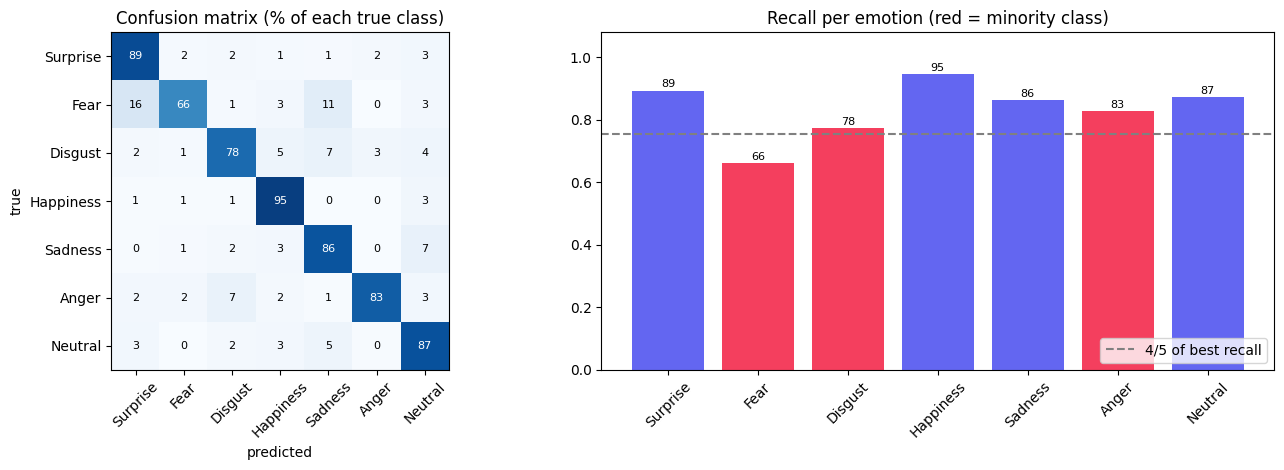

[saved] /content/drive/MyDrive/Sem3-CaseStudy/models/results_without_fairness.json


In [12]:
res_without = evaluate_system(SYSTEM_NAME, SYSTEM_MODELS, SYSTEM_BIAS)
show_results(res_without)
save_results(res_without, "results_without_fairness.json")
SYSTEM_RESULTS = res_without

## 7. Test a single image (prediction, probabilities, reliability)
Set `IMG_PATH` to your own aligned face photo, or leave `None` for a random test image. Run the cell again for another image.

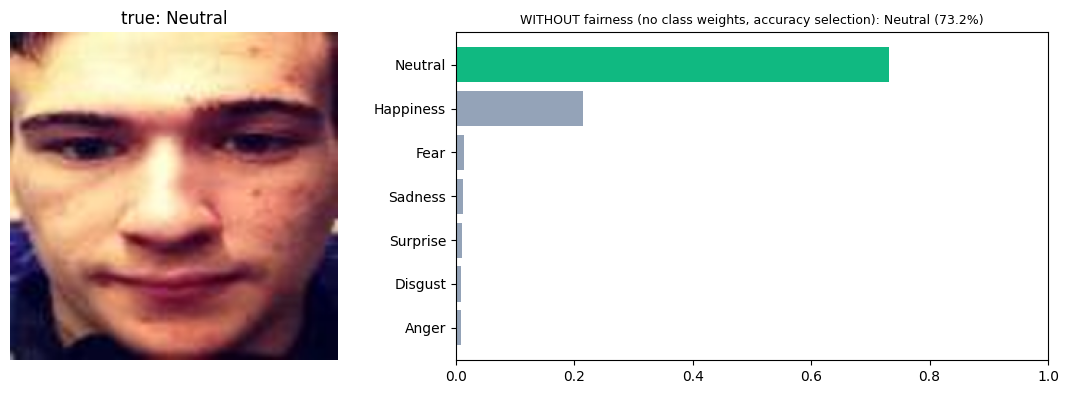

Prediction : Neutral | true: Neutral | CORRECT
Reliability: High
Confidence 73.2% | top-2 margin 51.7 pts (runner-up Happiness) | uncertainty 41.1%
Training share of Neutral: 20.6%
Note: On the test set the model recognises 87.2% of true Neutral faces and 85.9% of its Neutral predictions are correct.


In [13]:
from PIL import Image
from torchvision import transforms
from train_emotion_resnet50_vggface2 import ToVGGFace2Tensor
IMG_PATH = None          # <- put a path to your own face photo here, or leave None for a random test image
path = IMG_PATH or random.choice(glob.glob(f"{DATA_DIR}/test/*/*"))
true = None if IMG_PATH else EMOTIONS[int(os.path.basename(os.path.dirname(path))) - 1]
img = Image.open(path).convert("RGB")
tf = transforms.Compose([transforms.Resize((224, 224)), ToVGGFace2Tensor()])
x = tf(img).unsqueeze(0).to(device)

nets = [load_model(p) for p in SYSTEM_MODELS]
with torch.no_grad():
    probs = torch.stack([(torch.softmax(n(x), 1) + torch.softmax(n(torch.flip(x, dims=[3])), 1)) / 2 for n in nets]).mean(0)[0]
probs = torch.softmax(torch.log(probs + 1e-9) + torch.tensor(SYSTEM_BIAS or [0.0] * 7, device=device), 0).cpu().numpy()
k = int(probs.argmax())
ctx = prediction_context(EMOTIONS[k], probs, {"final": SYSTEM_RESULTS} if SYSTEM_RESULTS else None)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].imshow(img.resize((224, 224))); ax[0].axis("off"); ax[0].set_title(f"true: {true or '?'}")
order = np.argsort(probs)
ax[1].barh([EMOTIONS[i] for i in order], probs[order], color=["#10b981" if i == k else "#94a3b8" for i in order])
ax[1].set_xlim(0, 1); ax[1].set_title(f"{SYSTEM_NAME}: {EMOTIONS[k]} ({probs[k]*100:.1f}%)", fontsize=9)
plt.tight_layout(); plt.show()

print("Prediction :", EMOTIONS[k], "| true:", true, "|", "CORRECT" if true == EMOTIONS[k] else ("WRONG" if true else ""))
print(f"Reliability: {ctx['reliability']}{' - flag for human review' if ctx['needs_review'] else ''}")
print(f"Confidence {ctx['confidence']*100:.1f}% | top-2 margin {ctx['margin']*100:.1f} pts (runner-up {ctx['runner_up']}) "
      f"| uncertainty {ctx['uncertainty']*100:.1f}%")
print(f"Training share of {EMOTIONS[k]}: {ctx['train_share']*100:.1f}%{' (minority class)' if ctx['minority_class'] else ''}")
print("Note:", ctx["note"])
del nets

## 8. With vs without fairness – comparison
Needs `results_with_fairness.json` **and** `results_without_fairness.json` in the models folder, i.e. both notebooks have reached section 6.

metric                           WITHOUT      WITH    change
Accuracy                          88.85%    89.02%    +0.17
Balanced accuracy                 83.39%    82.42%    -0.97
Macro-F1                          83.27%    83.04%    -0.23
Worst-class recall                66.22%    58.11%    -8.11
Recall gap (best - worst)         28.29%    36.07%    +7.78
Recall ratio (worst / best)        0.701     0.617    -0.084
Minority-class mean recall        75.48%    71.93%    -3.55
Passes four-fifths rule            False     False

Predictions that differ: 264 of 3068 | fixed by fairness: 113 | broken by fairness: 108


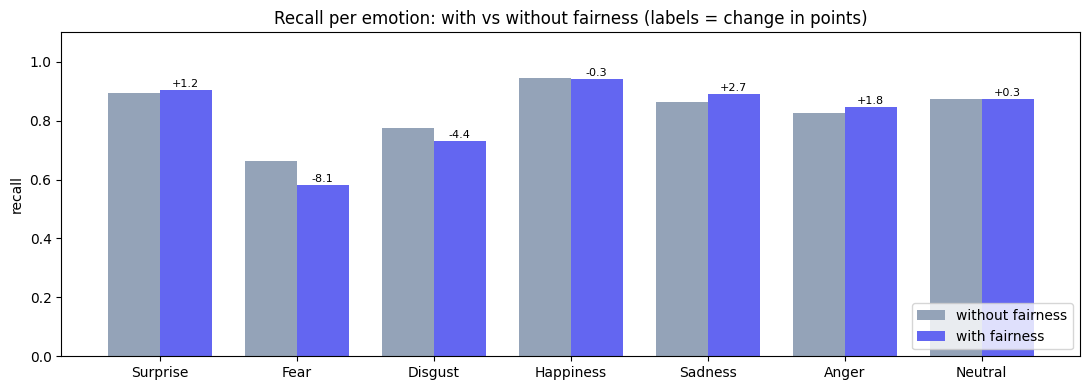

In [14]:
cmp = compare_saved()

## 9. Next
Run **FA_EFER_With_Fairness.ipynb** (its section 9 writes the full fairness report for the web app). With `emotion_r50_nofair.pth` in `models/`, the web app shows *without fairness* next to every prediction and in the batch PDF.